In [1]:
Sys.time()

[1] "2026-10-09 23:19:17 PDT"

In [2]:
suppressPackageStartupMessages(library(ggplot2))
suppressPackageStartupMessages(library(data.table))
suppressPackageStartupMessages(library(repr))
suppressPackageStartupMessages(library(ggrastr))
suppressPackageStartupMessages(library(dplyr))
suppressPackageStartupMessages(library(cowplot))
suppressPackageStartupMessages(library(ComplexHeatmap))
suppressPackageStartupMessages(library(circlize))
suppressPackageStartupMessages(library(RColorBrewer))
suppressPackageStartupMessages(library(ggplotify))

In [3]:
projdir <- '/u/project/cluo/terencew/igvf/2023_YR2/final_figures'

donors <- c('C29', 'C37', 'C38', 'C39')
donor_order <- donors
donor_hexes <- c('#2851B0', '#C445B8', '#70373D', '#CFCF42')

tmp_order <- c('Start', 'Sendai', 'Delayed', 'Fail1', 'Inter1', 'Inter2', 'Fail2', 'IPS')
clust_hexes <- c('#C4B921', '#707332', '#9C4F43', '#4F7EB8', '#B07620', '#D698D0', '#0F2061', '#7F5194')
names(clust_hexes) <- tmp_order

base_theme <- theme(
    axis.line = element_blank(),
    panel.border = element_blank(),
    panel.grid = element_blank(),
    panel.background = element_blank(),
    plot.background = element_blank(),
    axis.ticks.x = element_blank(),
    axis.ticks.y = element_blank(),
    legend.position = 'none')

### B: mCG difference between Start/early-IPS at ChromHMM enhancer classes

Warning message in fread(tmp_path):
"Detected 8 column names but the data has 9 columns (i.e. invalid file). Added 1 extra default column name for the first column which is guessed to be row names or an index. Use setnames() afterwards if this guess is not correct, or fix the file write command that created the file to create a valid file."
Warning message:
"Removed 1352954 rows containing non-finite outside the scale range
(`stat_ydensity()`)."
Warning message:
"Removed 1352954 rows containing non-finite outside the scale range
(`stat_boxplot()`)."


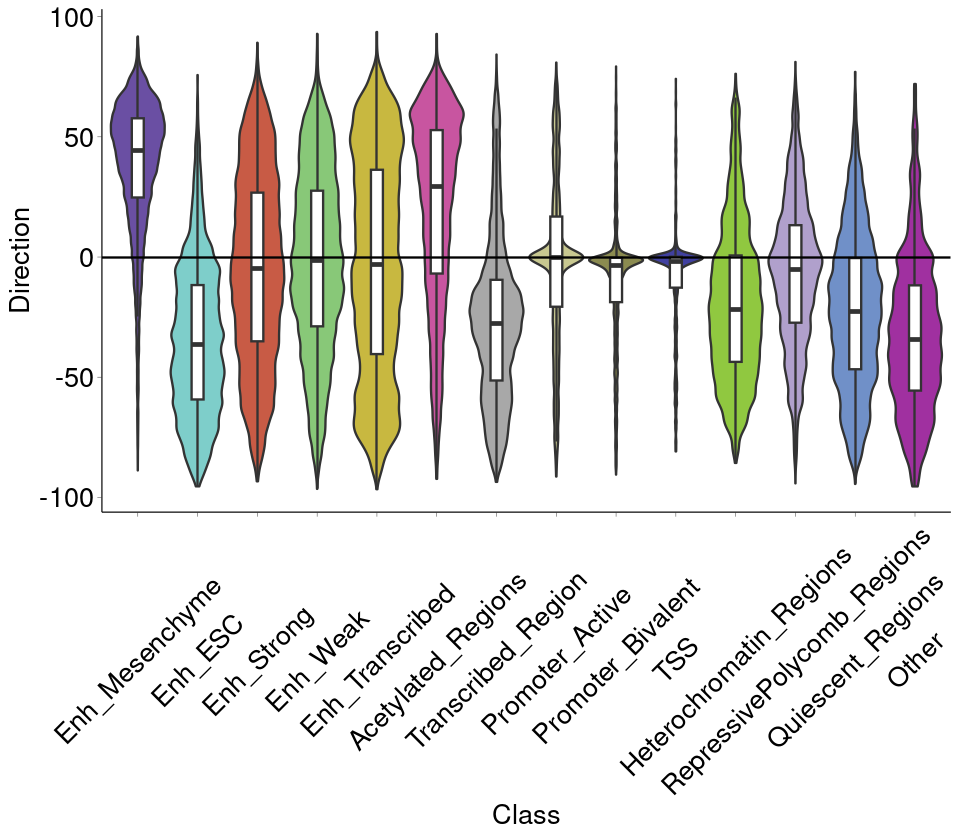

In [4]:
tmp_path <- "/u/project/cluo/IGVF_Share/personaldirs/justin/YS3v7_Figs/TrajFig/2026-06-18_YS3v7_fig3_summary_figure_pieces/YS3v7.Methylation_at_ChromHMM_Features.Violin.tsv"
atac.meth.summary <- as.data.frame(fread(tmp_path))

chromhmm_order <- c("Enh_Mesenchyme" , "Enh_ESC",  "Enh_Strong", "Enh_Weak" ,"Enh_Transcribed",
                "Acetylated_Regions",  "Transcribed_Region" ,  "Promoter_Active","Promoter_Bivalent",
                "TSS" ,  "Heterochromatin_Regions", "RepressivePolycomb_Regions" ,"Quiescent_Regions",  "Other")
chromhmm_colors <- c(
    "Enh_Mesenchyme"           = "#6A4FA3",
    "Enh_ESC"                  = "#7ECECA",
    "Enh_Strong"               = "#C85B45",
    "Enh_Weak"                 = "#88C878",
    "Enh_Transcribed"          = "#C8B840",
    "Acetylated_Regions"       = "#C855A0",
    "Transcribed_Region"       = "#A8A8A8",
    "Promoter_Active"          = "#C8C890",
    "Promoter_Bivalent"        = "#8B8B50",
    "TSS"                      = "#4040A0",
    "Heterochromatin_Regions"  = "#90C840",
    "RepressivePolycomb_Regions" = "#B0A0CC",
    "Quiescent_Regions"        = "#7090C8",
    "Other"                    = "#A030A0"
)

plot.violin <- atac.meth.summary[!is.na(atac.meth.summary$Class),]
plot.violin$Class <- factor(plot.violin$Class, levels=chromhmm_order)

w = 8
h = 7
options(repr.plot.width=w, repr.plot.height=h)

ggplot(plot.violin) +
  geom_violin(aes(x = Class, y = Direction, fill = Class), scale="width") +
  geom_boxplot(aes(x = Class, y = Direction), width=0.2, outlier.shape = NA) +
  base_theme +
   theme(axis.text.x = element_text(size=16, angle=45, hjust=0.5, vjust=0.5, color='black'),
        axis.text.y = element_text(size=16, color='black'),
        axis.title.x = element_text(size=16, color='black'),
        axis.title.y = element_text(size=16, color='black'),
        axis.line = element_line(linewidth=0.25, color='black'),
         axis.ticks.x = element_line(linewidth=0.1),
         axis.ticks.y = element_line(linewidth=0.1),
         legend.position = 'none',
        plot.title = element_text(size = 16, hjust = 0.2)) +
  scale_fill_manual(values = chromhmm_colors) +
  geom_hline(yintercept = 0)

### C: mCG at ATAC ChromHMM states per cluster/donor

Warning message:
"The input is a data frame, convert it to a matrix."


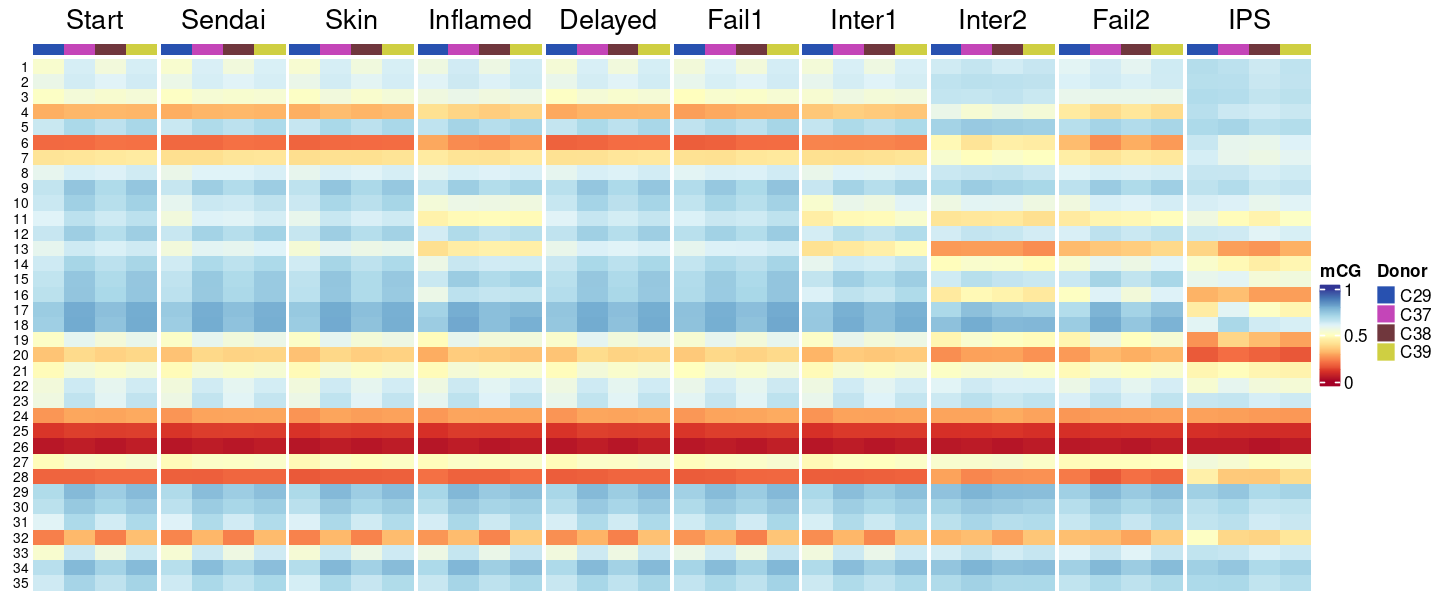

In [5]:
chromhmm_path = paste0(projdir, '/csv/figure4/atactstates_methylationavg_fixed.csv')
chromhmm = as.data.frame(fread(chromhmm_path, sep=','))
rownames(chromhmm) <- chromhmm$state
rownames(chromhmm) <- sub("^E", "", rownames(chromhmm))
chromhmm <- chromhmm[,-1]
colnames(chromhmm) <- sapply(strsplit(colnames(chromhmm), "\\."), `[`, 1)
mask <- !grepl('mature', colnames(chromhmm))
chromhmm <- chromhmm[,mask]

names(donor_hexes) <- donors
donor <- sub("^.*_", "", colnames(chromhmm))
donor <- factor(donor, levels = donor_order)

ha <- HeatmapAnnotation(
  Donor = donor,
  col = list(Donor = donor_hexes),
  show_annotation_name = FALSE,
  simple_anno_size = unit(0.2, "cm")
)

col_fun <- colorRamp2(
  seq(0, 1, length.out = 11),
  brewer.pal(11, "RdYlBu")
)
col_groups <- sub("_[^_]+$", "", colnames(chromhmm))
col_groups <- factor(col_groups, levels = unique(col_groups))

w = 12
h = 5
options(repr.plot.width=w, repr.plot.height=h)

Heatmap(chromhmm,
        name = 'mCG',
        col = col_fun,
        column_split = col_groups,
        top_annotation = ha,
        cluster_columns = FALSE,
        cluster_rows = FALSE,
        show_column_names = FALSE,
        show_row_names = TRUE,
        row_names_gp = gpar(fontsize = 8),
        column_title_gp = gpar(fontsize = 16),
        row_names_side = "left",
        heatmap_legend_param = list(tick_length = unit(0, "mm")))

### D: fraction of Start cells among neighbors

Warning message:
"Computation failed in `stat_summary()`.
Caused by error in `fun.data()`:
! The package "Hmisc" is required."
Warning message:
"Computation failed in `stat_summary()`.
Caused by error in `fun.data()`:
! The package "Hmisc" is required."


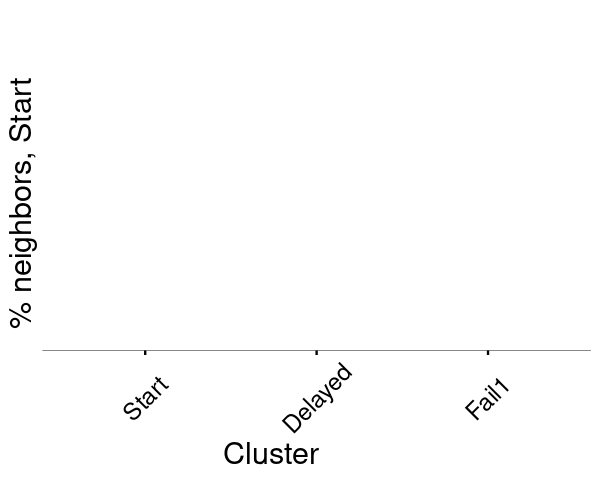

In [6]:
select_cols <- c('cluster', 'start_prop')
mod_hexes <- c('#8651CF', '#48B028', '#51ADCF', '#DEAE1F')
mod_order <- c('RNA', 'ATAC', 'Methylation', '3C')
fail1_order <- c('Start', 'Delayed', 'Fail1')

rna_nn_path = paste0(projdir, '/csv/figure3/rna_nn_start_prop.csv')
rna_nn = as.data.frame(fread(rna_nn_path, sep='\t'))
rna_nn$cluster <- factor(rna_nn$cluster, levels=tmp_order)
rna_nn <- rna_nn %>% select(all_of(select_cols))
rna_nn$mod <- 'RNA'

atac_nn_path = paste0(projdir, '/csv/figure3/atac_nn_start_prop.csv')
atac_nn = as.data.frame(fread(atac_nn_path, sep='\t'))
atac_nn$cluster <- factor(atac_nn$cluster, levels=tmp_order)
atac_nn <- atac_nn %>% select(all_of(select_cols))
atac_nn$mod <- 'ATAC'

mcg_nn_path = paste0(projdir, '/csv/figure3/mcg_nn_start_prop.csv')
mcg_nn = as.data.frame(fread(mcg_nn_path, sep='\t'))
mcg_nn$cluster <- factor(mcg_nn$cluster, levels=tmp_order)
mcg_nn <- mcg_nn %>% select(all_of(select_cols))
mcg_nn$mod <- 'Methylation'

hic_nn_path = paste0(projdir, '/csv/figure3/hic_nn_start_prop.csv')
hic_nn = as.data.frame(fread(hic_nn_path, sep='\t'))
hic_nn$cluster <- factor(hic_nn$cluster, levels=tmp_order)
hic_nn <- hic_nn %>% select(all_of(select_cols))
hic_nn$mod <- '3C'

nn_list <- list(rna_nn, atac_nn, mcg_nn, hic_nn)
merged_nn <- do.call(rbind, nn_list)
merged_nn$mod <- factor(merged_nn$mod, levels=mod_order)
merged_nn$cluster <- factor(merged_nn$cluster, levels=fail1_order)

w = 5
h = 4
options(repr.plot.width=w, repr.plot.height=h)

ggplot(merged_nn, aes(x = cluster, y = start_prop, color = mod, group=mod)) +
  stat_summary(fun.data = mean_cl_normal, geom = "line") +
  stat_summary(fun.data = mean_cl_normal, geom = "errorbar", width = 0.2) +
    scale_color_manual(values=mod_hexes) +
  labs(x = "Cluster", y = "% neighbors, Start", title = '', color='Modality') +
  theme_minimal() +
  base_theme +
  theme(
      axis.title.x = element_text(size = 18, color='black', hjust=0.4),
      axis.title.y = element_text(size = 18, color='black', hjust=0.5),
      axis.text.x = element_text(size = 14, angle=45, color='black',hjust=0.5, vjust=0.5),
      axis.text.y = element_text(size = 14, color='black',hjust=0.5),
      plot.title = element_text(size = 24, hjust=0.4, face='plain'),
      axis.line = element_line(linewidth=0.1, color='black'),
        axis.ticks.x = element_line(),
        axis.ticks.y = element_line(),
        legend.position = 'right'
      )

### E: mCG UMAP of Start, Delayed, Fail1

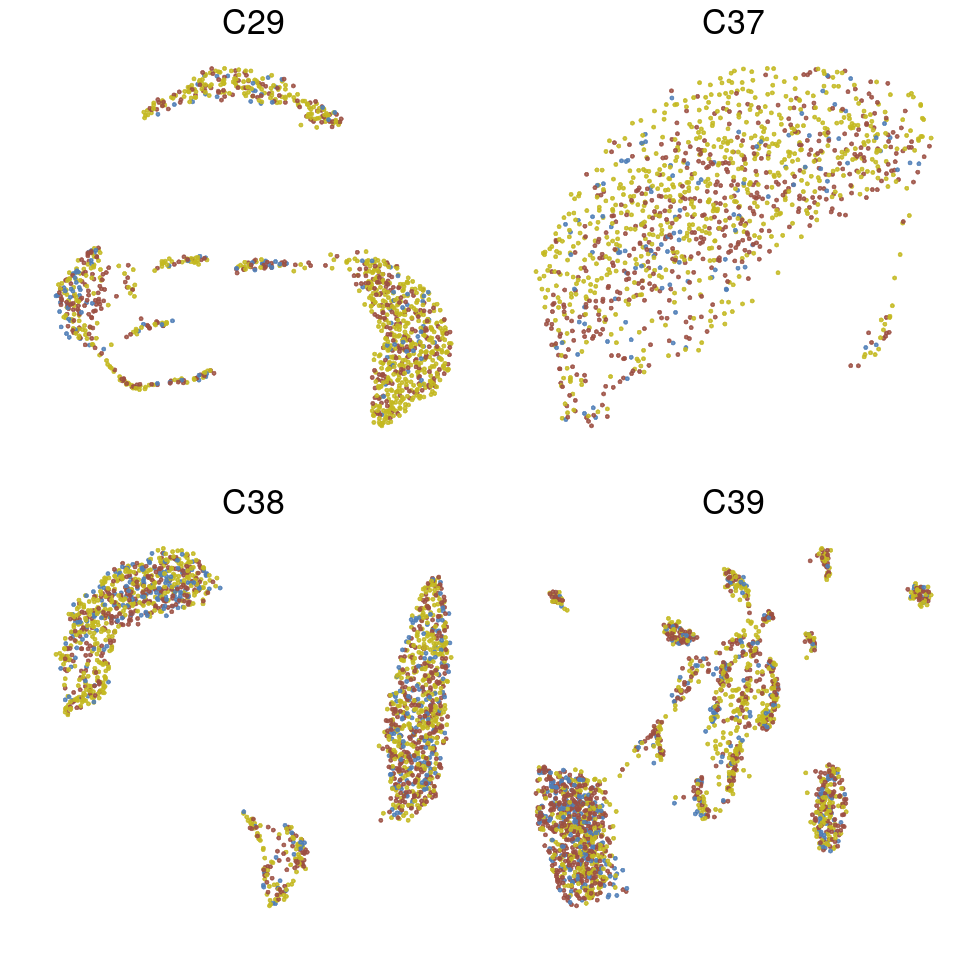

In [7]:
fail1_order <- c('Start', 'Delayed', 'Fail1')

mcg_umap_path = paste0(projdir, '/csv/figure3/mcg_fail1_start_umap.csv')
mcg_umap = as.data.frame(fread(mcg_umap_path, sep='\t'))
mcg_umap$rna_cluster <- factor(mcg_umap$rna_cluster, levels=fail1_order)

set.seed(1)
shuffled_mcg_umap <- mcg_umap[sample(nrow(mcg_umap)), ]

plot_umap <- function(tmp_df, d) {
    donor_df <- tmp_df[tmp_df$line == d,]
    ggplot(donor_df, aes(x = umap0, y = umap1, color = rna_cluster)) +
    geom_point_rast(alpha=0.8, size=0.5) +
  labs(x = "", y = "", title=d, color='') +
  theme_bw() +
  base_theme +
    theme(
        axis.text.x = element_blank(),
        axis.text.y = element_blank(),
        plot.title = element_text(size=20, color='black', hjust=0.5),
    legend.position = 'none') +
    scale_color_manual(values=clust_hexes)
    }

plot_list <- list()

for (i in seq_along(donors)) {
    d <- donors[i]
    plot_list[[i]] <- plot_umap(shuffled_mcg_umap, d)
}
w = 8
h = 8
options(repr.plot.width=w, repr.plot.height=h)
combined_plot <- plot_grid(plotlist = plot_list, ncol=2, nrow=2)
combined_plot

### F: correlation of 100kb mCG between cell types

Warning message:
"The input is a data frame, convert it to a matrix."


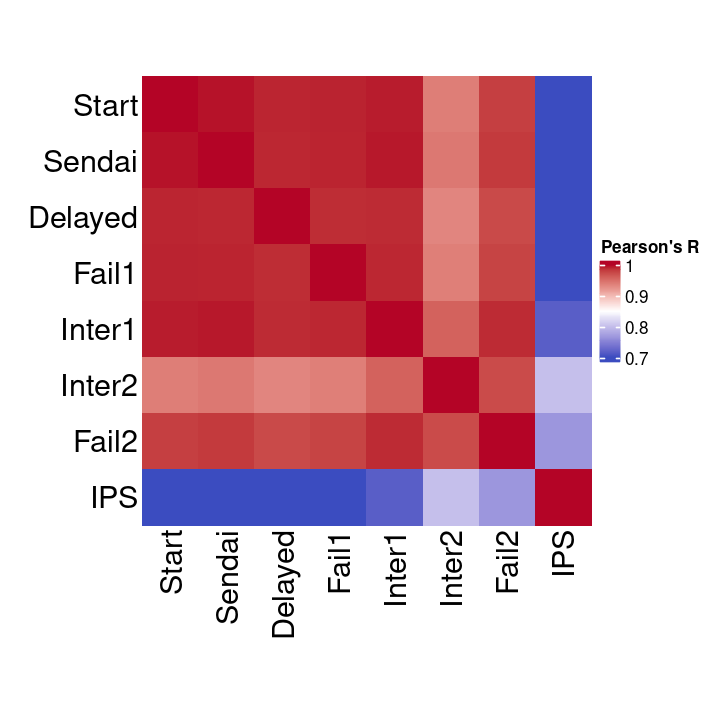

In [8]:
mcg_corr_path = paste0(projdir, '/csv/figure3/mcg_celltype_5kb_bins_corr.csv')
mcg_corr = as.data.frame(fread(mcg_corr_path, sep='\t'))
rownames(mcg_corr) <- mcg_corr$V1
mcg_corr <- mcg_corr[,-1]

w = 6
h = 6
options(repr.plot.width=w, repr.plot.height=h)

ht <- Heatmap(mcg_corr,
        name = "Pearson's R",
        col = colorRamp2(c(0.7, 0.85, 1), c("#3B4CC0", "white", "#B40426")),
        cluster_rows = FALSE,
        cluster_columns = FALSE,
        show_row_names = TRUE,
        show_column_names = TRUE,
        row_names_side = "left",
        row_names_gp = gpar(fontsize = 18),
        column_names_gp = gpar(fontsize = 18, rot = 90),
        heatmap_width = unit(12, "cm"),
        heatmap_height = unit(12, "cm"))

ht

### G: PMD metagene across the Fail1 branch

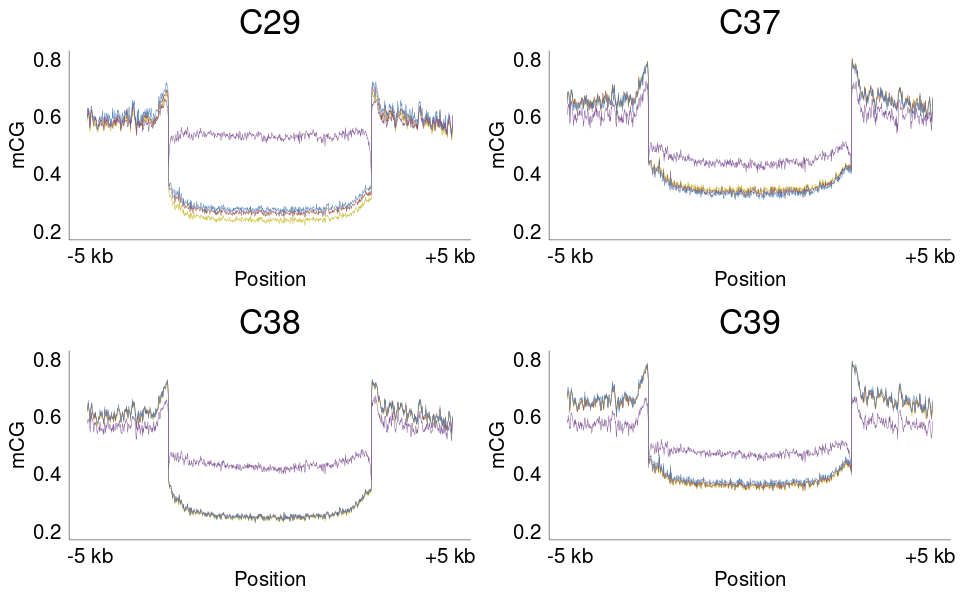

In [9]:
pmd_flank_path = paste0(projdir, '/csv/figure3/pmds_flank_metagene.csv')
pmd_flank = read.csv(pmd_flank_path, sep='\t')
pmd_flank$donor <- factor(pmd_flank$donor, levels=donors)
pmd_flank$cluster <- factor(pmd_flank$cluster, levels=tmp_order)

slack = 6
tmp_breaks <- c(min(pmd_flank$tmp) + slack, max(pmd_flank$tmp) - slack)
tmp_hexes <- c('#C4B921', '#9C4F43', '#4F7EB8', '#7F5194')

plot_pmds <- function(pmd_flank, d) {

  tmp_flank <- pmd_flank[pmd_flank$donor == d, ]

  whitelist <- c('Start', 'Delayed', 'Fail1', 'IPS')
  final_flank <- tmp_flank[tmp_flank$cluster %in% whitelist, ]

  ggplot(final_flank, aes(x = tmp, y = X0, color = cluster, group = cluster)) +
   geom_line(linewidth=0.1) +
    labs(x = "Position", y = "mCG", title = d) +
    coord_cartesian(ylim = c(0.2, 0.8)) +
    scale_x_continuous(breaks = tmp_breaks, labels = c("-5 kb", "+5 kb")) +
    theme_bw() +
    base_theme +
    scale_color_manual(values = tmp_hexes) +
    theme(
      axis.text.x = element_text(size=12, color='black'),
        axis.text.y = element_text(size=12,angle=0, color='black'),
        axis.title.x = element_text(size=12),
        axis.title.y = element_text(size=12),
        axis.line = element_blank(),
         axis.line.x = element_line(linewidth=0.1),
         axis.line.y = element_line(linewidth=0.1),
      legend.position = 'none',
      plot.title = element_text(size = 20, hjust = 0.5)
    )
}

plot_list <- list()
for (i in seq_along(donors)) {
    d = donors[i]
    p <- plot_pmds(pmd_flank, d)
    plot_list[[i]] <- p
}

w = 8
h = 5
options(repr.plot.width=w, repr.plot.height=h)

combined_plot <- plot_grid(plotlist=plot_list, nrow=2, ncol=2)
combined_plot

### H: Sendai-enhancer mCG across the Fail1 branch

Warning message:
"The input is a data frame, convert it to a matrix."
Warning message:
"The input is a data frame, convert it to a matrix."


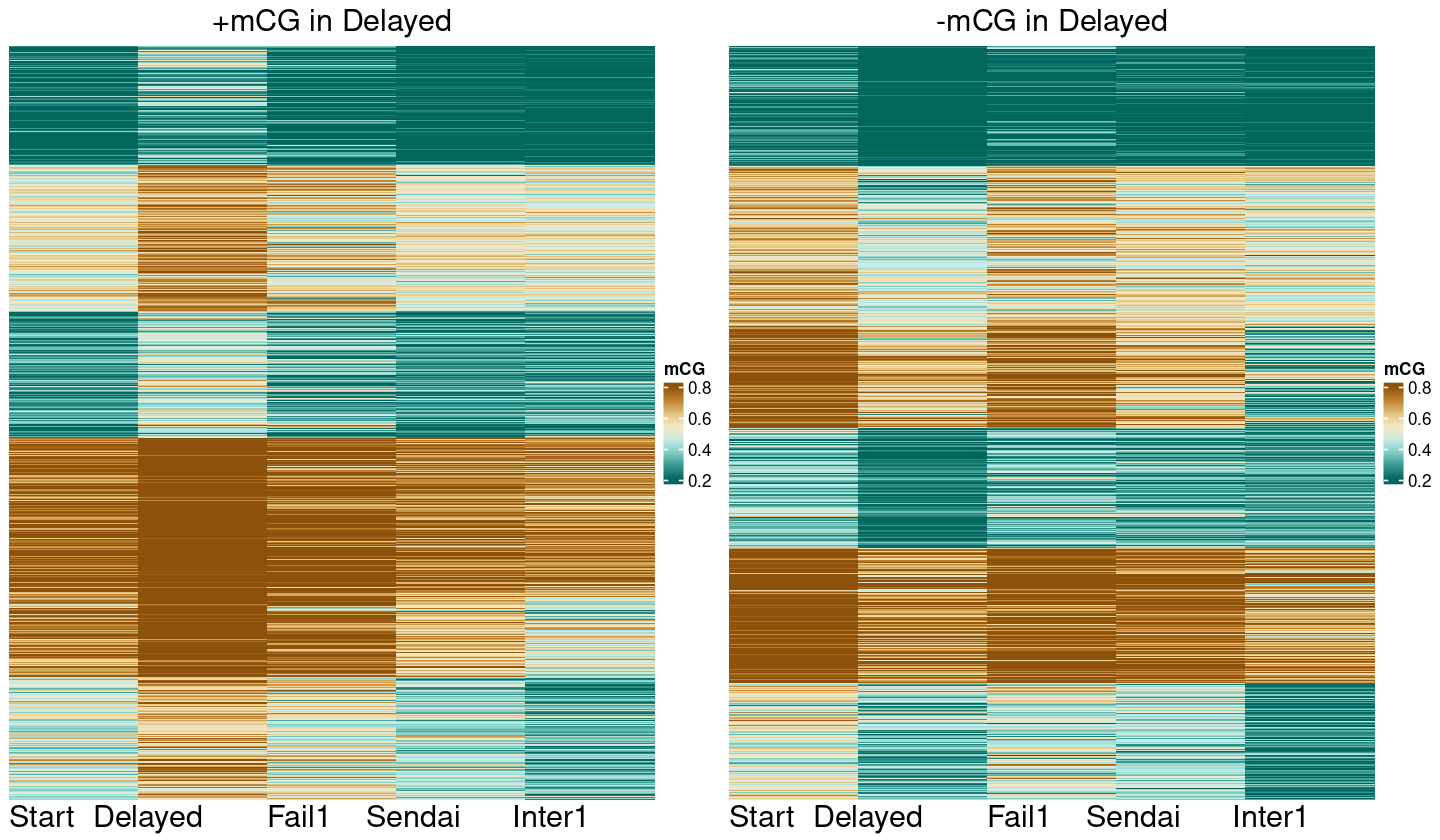

In [10]:
select <- c('Start', 'Delayed', 'Fail1', 'Sendai', 'Inter1')

sendai_fail_pos_path = paste0(projdir, '/csv/figure3/sendai_enhancers_fail_pos.csv')
sendai_fail_pos = as.data.frame(fread(sendai_fail_pos_path))
sendai_fail_pos <- sendai_fail_pos[,-1]
sendai_fail_pos <- sendai_fail_pos[,select]

sendai_fail_neg_path = paste0(projdir, '/csv/figure3/sendai_enhancers_fail_neg.csv')
sendai_fail_neg = as.data.frame(fread(sendai_fail_neg_path))
sendai_fail_neg <- sendai_fail_neg[,-1]
sendai_fail_neg <- sendai_fail_neg[,select]

col_fun <- colorRamp2(seq(0.2, 0.8, length.out = 8), rev(brewer.pal(8, "BrBG")))

plot_sendai <- function(df, title) {
  ht <- Heatmap(
    df,
    name = "mCG",
    col = col_fun,
    row_names_side = "left",
    column_names_side = "bottom",
    show_row_names = FALSE,
    show_column_names = TRUE,
    cluster_rows = FALSE,
    cluster_columns = FALSE,
    row_names_gp = gpar(fontsize = 12),
    column_names_gp = gpar(fontsize = 18),
    column_title_gp = gpar(fontsize = 18),
    column_names_rot = 0,
    row_title_rot = 90,
    column_title = title)
  as.ggplot(ht) + base_theme
}

p1 <- plot_sendai(sendai_fail_pos, '+mCG in Delayed')
p2 <- plot_sendai(sendai_fail_neg, '-mCG in Delayed')

w = 12
h = 7
options(repr.plot.width = w, repr.plot.height = h)

plot_grid(p1, p2, ncol=2)

### I: compartment switching across Start / Sendai / Inter1

Warning message:
"package 'ggalluvial' was built under R version 4.2.0"
Warning message in geom_alluvium(aes(fill = pattern, color = reversion), width = 1/4, :
"Ignoring unknown parameters: `linewidth`"
Warning message in geom_stratum(width = 1/4, fill = "white", color = "black", linewidth = 0.3):
"Ignoring unknown parameters: `linewidth`"
Warning message in to_lodes_form(data = data, axes = axis_ind, discern = params$discern):
"Some strata appear at multiple axes."
Warning message in to_lodes_form(data = data, axes = axis_ind, discern = params$discern):
"Some strata appear at multiple axes."
Warning message:
"Computation failed in `stat_stratum()`.
Caused by error in `default_missing()`:
! could not find function "default_missing""
Warning message in to_lodes_form(data = data, axes = axis_ind, discern = params$discern):
"Some strata appear at multiple axes."
Warning message:
"Computation failed in `stat_stratum()`.
Caused by error in `default_missing()`:
! could not find function "def

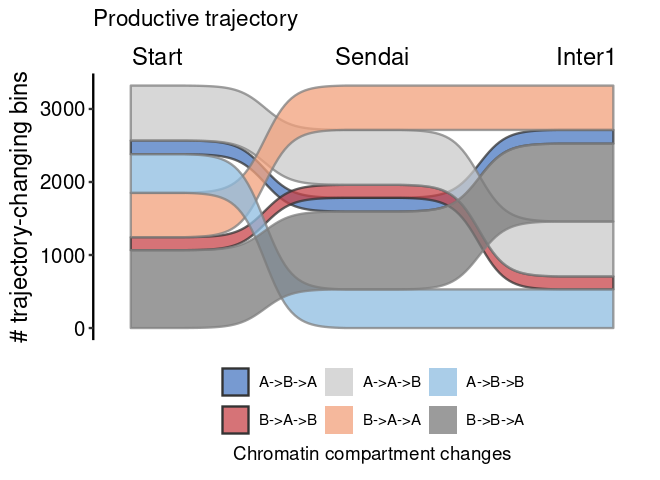

In [11]:
suppressPackageStartupMessages(library(ggalluvial))

comps_path = paste0(projdir, '/csv/figure3/fail1_branch_pivot_table.csv')
comps = as.data.frame(fread(comps_path, sep='\t'))
comps <- subset(comps, Start != '' & Sendai != '' & Inter1 != '')

traj <- comps %>%
  filter(!(Start == Sendai & Sendai == Inter1)) %>%
  mutate(pattern = paste(Start, Sendai, Inter1, sep = '->')) %>%
  count(Start, Sendai, Inter1, pattern, name = 'n') %>%
  mutate(
    across(c(Start, Sendai, Inter1), ~ factor(.x, levels = c('A', 'B'))),
    reversion = pattern %in% c('A->B->A', 'B->A->B'),
    pattern = factor(pattern, levels = c('A->B->A', 'B->A->B',
                                         'A->A->B', 'B->A->A',
                                         'A->B->B', 'B->B->A'))
  ) %>%
  arrange(reversion)

flow_cols <- c('A->B->A' = '#4A78C2',
               'B->A->B' = '#C8444A',
               'A->A->B' = '#C9C9C9',
               'B->A->A' = '#F2A07B',
               'A->B->B' = '#8DBCE0',
               'B->B->A' = '#7A7A7A')

w = 5.5
h = 4
options(repr.plot.width = w, repr.plot.height = h)

ggplot(traj, aes(axis1 = Start, axis2 = Sendai, axis3 = Inter1, y = n)) +
  geom_alluvium(aes(fill = pattern, color = reversion),
                width = 1/4, alpha = 0.75, linewidth = 0.7,
                curve_type = 'sigmoid') +
  geom_stratum(width = 1/4, fill = 'white', color = 'black', linewidth = 0.3) +
  geom_text(stat = 'stratum',
            aes(label = paste0(after_stat(stratum), '\n',
                               scales::comma(after_stat(count)))),
            size = 3.5) +
  scale_x_discrete(limits = c('Start', 'Sendai', 'Inter1'),
                   expand = c(0.1, 0.1), position = 'top') +
  scale_fill_manual(values = flow_cols, name = 'Chromatin compartment changes') +
  scale_color_manual(values = c(`TRUE` = 'grey20', `FALSE` = NA), guide = 'none') +
  labs(y = '# trajectory-changing bins', x = NULL, title = 'Productive trajectory') +
  theme_classic() +
  theme(
    axis.text.x  = element_text(size = 14, color = 'black'),
    axis.text.y  = element_text(size = 12, color = 'black'),
    axis.title.y = element_text(size = 14, color = 'black'),
    axis.line.x  = element_blank(),
    axis.ticks.x = element_blank(),
    legend.position = 'bottom',
    legend.title.position = 'bottom',
    legend.title = element_text(hjust = 0.5)
  ) +
  guides(fill = guide_legend(ncol = 3, byrow = FALSE,
                             override.aes = list(color = c('grey20', 'grey20', NA, NA, NA, NA))))

### K: mCG at early-IPS peaks in the Fail2 branch

Warning message:
"The input is a data frame, convert it to a matrix."


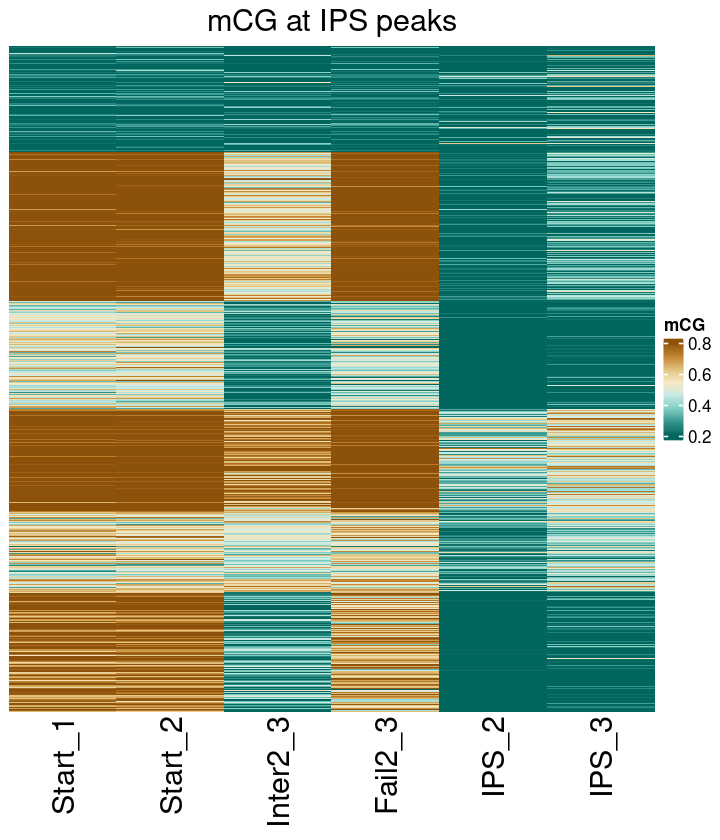

In [12]:
enh_mcg_path = paste0(projdir, '/csv/figure3/rev_class_chromhmm_peaks_mcg.csv')
enh_mcg = as.data.frame(fread(enh_mcg_path, sep='\t'))
enh_mcg <- enh_mcg[,-1]

col_fun <- colorRamp2(seq(0.2, 0.8, length.out = 8), rev(brewer.pal(8, "BrBG")))

w = 6
h = 7
options(repr.plot.width = w, repr.plot.height = h)

ht <- Heatmap(
    enh_mcg,
    name = "mCG",
    col = col_fun,
    row_names_side = "left",
    column_names_side = "bottom",
    show_row_names = FALSE,
    show_column_names = TRUE,
    cluster_rows = FALSE,
    cluster_columns = FALSE,
    row_names_gp = gpar(fontsize = 12),
    column_names_gp = gpar(fontsize = 18),
    column_title_gp = gpar(fontsize = 18),
    column_names_rot = 90,
    row_title_rot = 90,
    column_title = 'mCG at IPS peaks',
    )

ht

In [13]:
sessionInfo()

R version 4.1.0 (2021-05-18)
Platform: x86_64-pc-linux-gnu (64-bit)
Running under: CentOS Linux 7 (Core)

Matrix products: default
BLAS/LAPACK: /u/local/compilers/intel/2020.4/compilers_and_libraries_2020.4.304/linux/mkl/lib/intel64_lin/libmkl_gf_lp64.so

locale:
[1] C

attached base packages:
[1] grid      stats     graphics  grDevices utils     datasets  methods  
[8] base     

other attached packages:
 [1] ggalluvial_0.12.3     ggplotify_0.1.0       RColorBrewer_1.1-3   
 [4] circlize_0.4.15       ComplexHeatmap_2.10.0 cowplot_1.1.1        
 [7] dplyr_1.1.4           ggrastr_1.0.2         repr_1.1.4           
[10] data.table_1.14.4     ggplot2_3.5.0        

loaded via a namespace (and not attached):
 [1] tidyr_1.3.2         jsonlite_1.8.8      splines_4.1.0      
 [4] foreach_1.5.2       Formula_1.2-5       stats4_4.1.0       
 [7] latticeExtra_0.6-30 yulab.utils_0.0.5   vipor_0.4.7        
[10] backports_1.4.1     pillar_1.9.0        lattice_0.20-45    
[13] glue_1.8.1          

In [14]:
Sys.time()

[1] "2026-10-09 23:19:46 PDT"